In [33]:
import pandas as pd
import numpy as np



In [34]:
%pip install scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [36]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [37]:
df.shape


(5000, 9)

In [38]:
df.isnull().sum()


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [39]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [40]:
for col in ['lead_source','industry','employment_status','location']:
    df[col] = df[col].fillna('NA')

for col in ['annual_income','number_of_courses_viewed','interaction_count','lead_score','converted']:
    df[col] = df[col].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

QUESTION 1.

In [41]:
df['industry'].mode()

0    technology
Name: industry, dtype: str

QUESTION 2.

In [46]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
df.corr(numeric_only=True)

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


<Axes: >

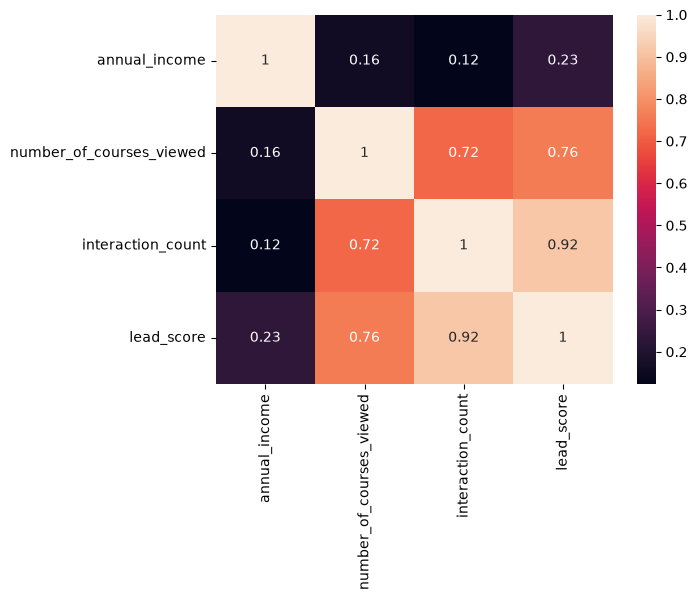

In [50]:
import seaborn as sns
sns.heatmap(corr, annot=True)

QUESTION 3.

In [53]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [56]:
from sklearn.metrics import mutual_info_score

categorical = ['lead_source', 'industry', 'employment_status', 'location']

for col in categorical:
    score = mutual_info_score(df_train[col], y_train)
    print(col, round(score, 2))

lead_source 0.03
industry 0.0
employment_status 0.02
location 0.0


QUESTION 4.

In [57]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
def train_and_score(features, C=1.0):
   
    train_dicts = df_train[features].to_dict(orient='records')
    val_dicts = df_val[features].to_dict(orient='records')

    
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)   
    X_val = dv.transform(val_dicts)           

    
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    
    y_pred = model.predict(X_val)
    return accuracy_score(y_val, y_pred)

In [59]:
features = categorical + numerical
base_accuracy = train_and_score(features)
print(base_accuracy)
print(round(base_accuracy, 2))

0.645
0.65


QUESTION 5.

In [62]:
differences = []

for f in features:
    smaller = [x for x in features if x != f]      
    new_acc = train_and_score(smaller)             
    diff = base_accuracy - new_acc                 
    differences.append((f, new_acc, diff))


pd.DataFrame(differences, columns=['feature_removed', 'accuracy_without', 'difference'])

,feature_removed,accuracy_without,difference
0,lead_source,0.642,0.003
1,industry,0.645,0.000
2,employment_status,0.645,0.000
3,location,0.645,0.000
4,annual_income,0.724,-0.079
5,number_of_courses_viewed,0.643,0.002
6,interaction_count,0.601,0.044
7,lead_score,0.644,0.001


QUESTION 6.


In [61]:
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    acc = train_and_score(features, C=C)
    print(C, round(acc, 3))

1e-06 0.598
1e-05 0.598
0.0001 0.613
0.001 0.645
